# Compositor dosyalarıyla ilk deneme

`duyuru.comp` ve `karga.comp` paketlerinin içindeki katmanlardan, asıl çözünürlükte yeni PNG görüntüler oluşturduk. Sonra arka plan katmanını kontrol olarak alıp birleştirilmiş görüntüyle ELA davranışını karşılaştırdık.

Bu ayrı bir deneme raporu; önceki notebook'ların ayarlarını değiştirmiyor. Görseller dosyaya gömülü, kod çalıştırmadan okunabilir.


## Render nasıl alındı?

Dosyaların `manifest.json` bölümünde katmanların yeri, boyutu, dönüşü ve saydamlığı var. Resimler `images/` içinde. Bunları birleştirerek yeni görüntüler ürettik; küçük QuickLook önizlemelerini büyütüp çıktı diye kullanmadık.

Bu iki paketteki görünür katmanlar Normal birleştirme kullanıyor. Konum, boyut, çevirme, merkez etrafında dönme ve saydamlık uygulandı. Metin için pakette saklanan yazı resmi kullanıldı; font yeniden oluşturulmadı. Compositor uygulamasının kendi dışa aktarma motoru çalıştırılmadı; örneklerin kullandığı katman özellikleriyle ayrı bir birleştirme yapıldı. Yeniden örnekleme nedeniyle native çıktıyla küçük piksel farkları olabilir.

Kayıtlı QuickLook görüntüleri yalnızca yerleşim kontrolü için karşılaştırıldı. Bunun hata ölçümü, ELA'nın tespit başarısı değildir.


## ELA'yı nasıl denedik?

Analiz, tam çözünürlüklü piksellerde **5, 10, 20, 40, 60, 80, 90 ve 95** JPEG ayarlarıyla yapıldı. Her kalite aynı PNG girdiden başladı. Görseller yalnızca rapora çizilirken küçültüldü.

Burada girişler, `.comp` paketlerindeki PNG katmanları ve yeni PNG render. Bu yüzden ölçtüğümüz şey **PNG → JPEG dönüşümünün piksel farkı**. Özgün kamera JPEG dosyalarının sıkıştırma geçmişini doğruladığımız anlamına gelmiyor.

Beyaz maskeler, üst katmanların manifestten bildiğimiz yerlerini gösterir. Algoritmanın bulduğu bölgeler değildir. Kontrol de projenin arka plan katmanıdır; dosyanın hiç düzenlenmediği doğrulanmış bir fotoğraf olarak kabul edilmez.


## duyuru.comp

**2160 × 3840 piksel**, 8 katman.

[Tam çözünürlüklü PNG render'ı aç](outputs/compositor_tests/duyuru_render.png)

Soldan sağa: arka plan, yeni render, üst katmanların alanları ve kalite 90 ile ELA. Normal kenarların da fark ürettiğine bak.

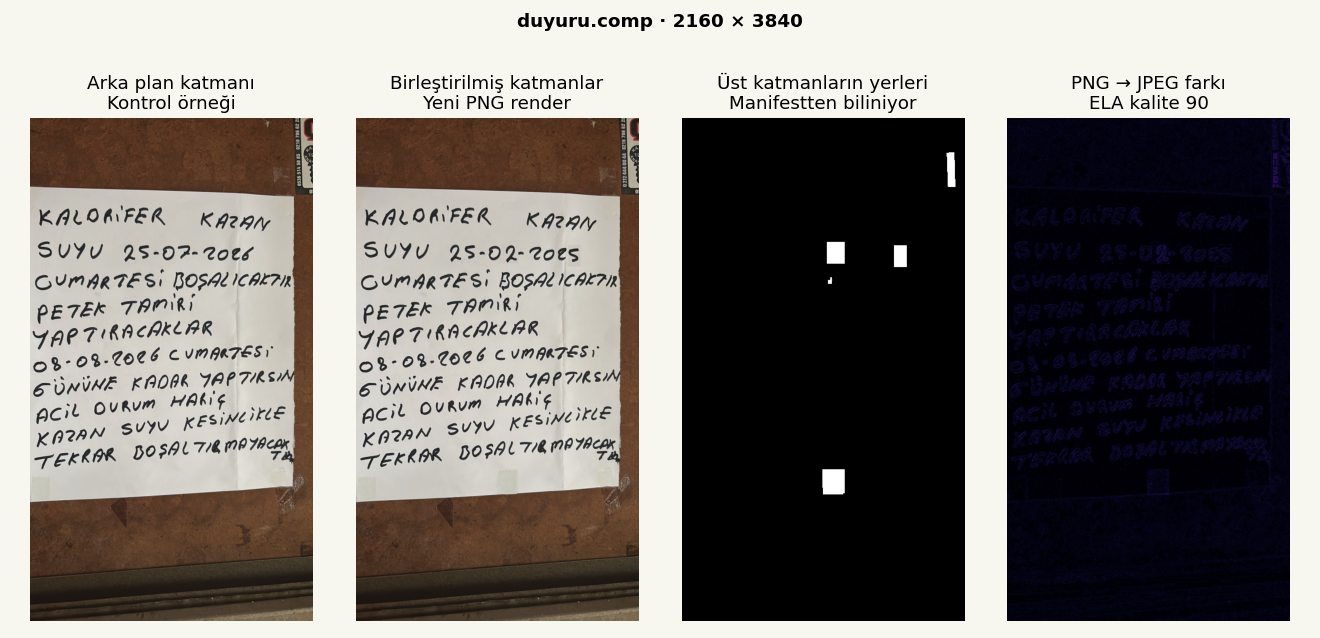


### Aynı alanı sayıyla karşılaştıralım

Bu sayılar üst katmanların kapladığı piksellerdeki ortalama ELA farkıdır. Büyük sayı daha çok yeniden sıkıştırma farkı demek; sahte olma yüzdesi değildir. Bazı ayarlarda kontrol ve render birbirine yakın çıkabilir.

| JPEG kalitesi | Katman alanında kontrol farkı | Katman alanında render farkı |
|---|---:|---:|
| 5 | 7.505 | 10.567 |
| 10 | 6.086 | 6.486 |
| 20 | 3.629 | 3.951 |
| 40 | 2.363 | 2.785 |
| 60 | 1.986 | 2.418 |
| 80 | 1.283 | 1.612 |
| 90 | 0.581 | 1.088 |
| 95 | 0.367 | 0.753 |

**Bu örnekte Q90:** katman alanının ortalama farkı kontrolde **0.581**, render'da **1.088**. Bu ölçüm arttı. Bu bir tespit doğruluğu ölçümü değil.


### Bütün kalite ayarları

Üst iki sıra kontrolün, alt iki sıra yeni render'ın haritaları. Hepsinde renk ölçeği **0–20**; üstündeki değerler aynı en parlak renkte görünür. Tablodaki ölçümler kırpılmamış değerlerden gelir.

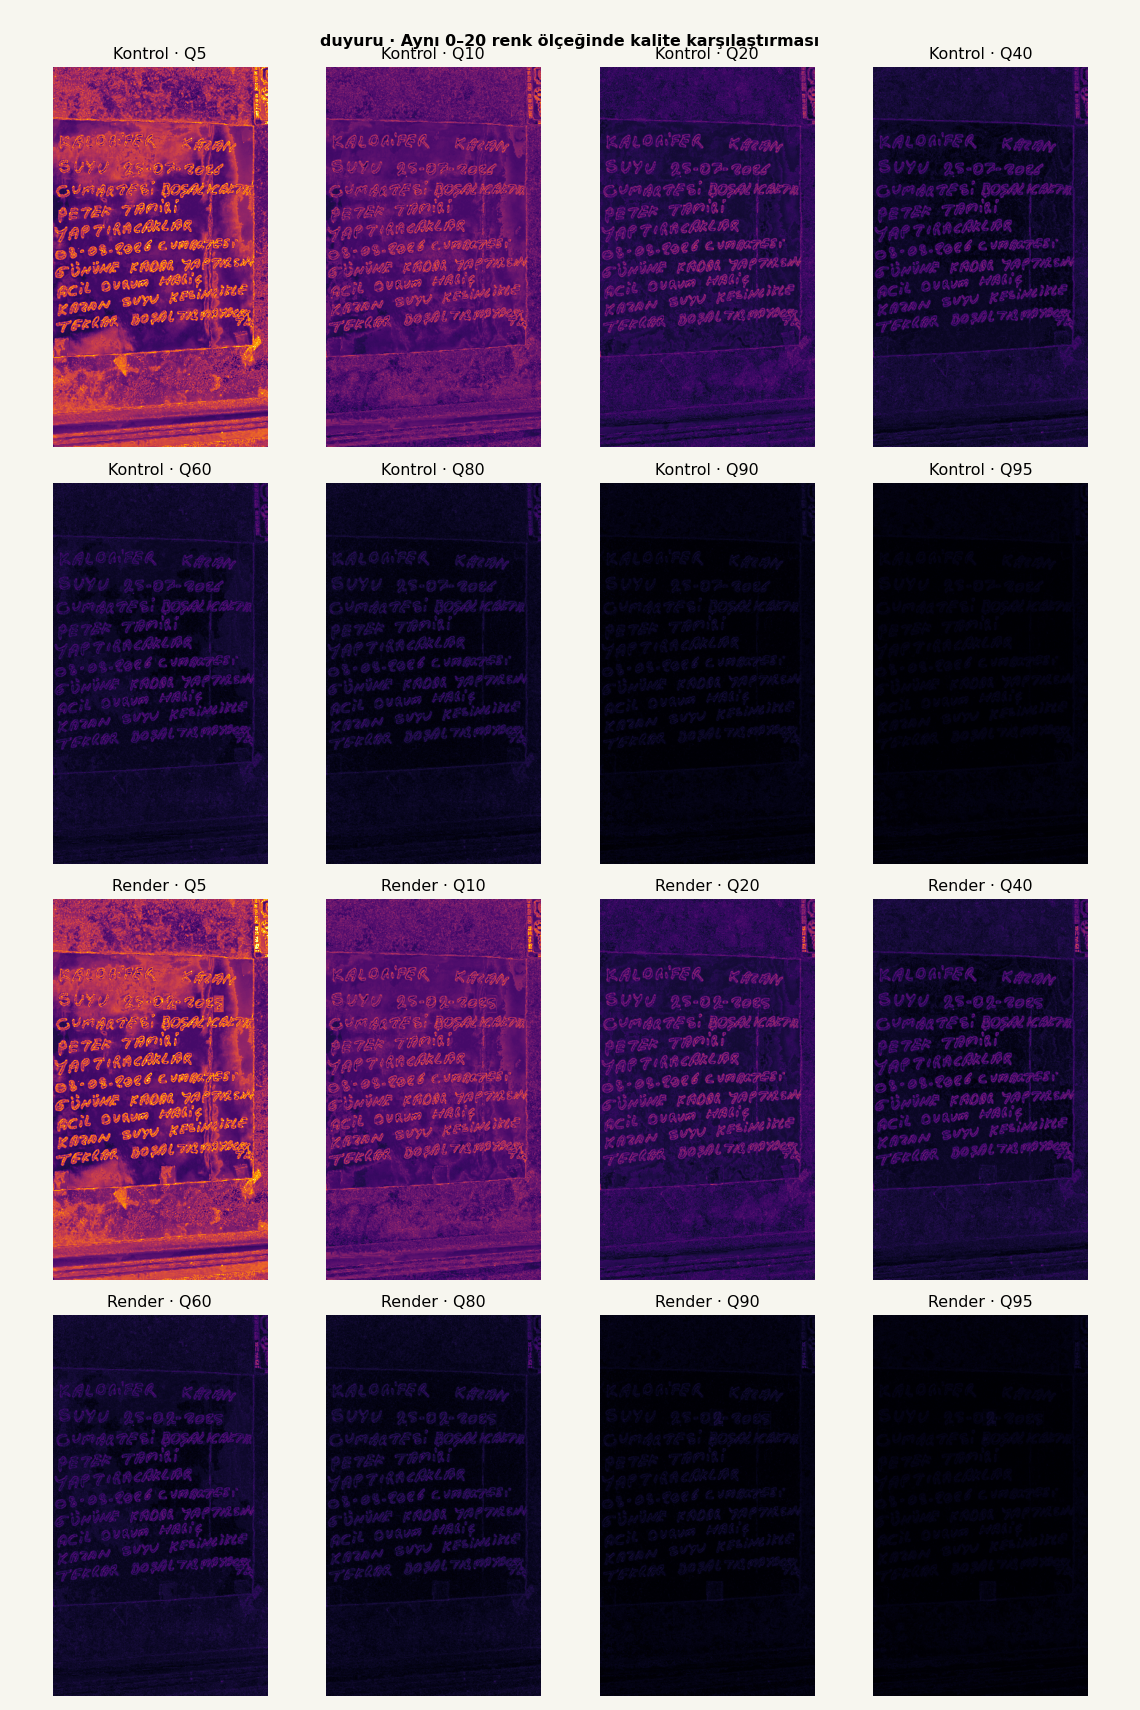


## karga.comp

**4284 × 5712 piksel**, 2 katman.

[Tam çözünürlüklü PNG render'ı aç](outputs/compositor_tests/karga_render.png)

Soldan sağa: arka plan, yeni render, üst katmanların alanları ve kalite 90 ile ELA. Normal kenarların da fark ürettiğine bak.

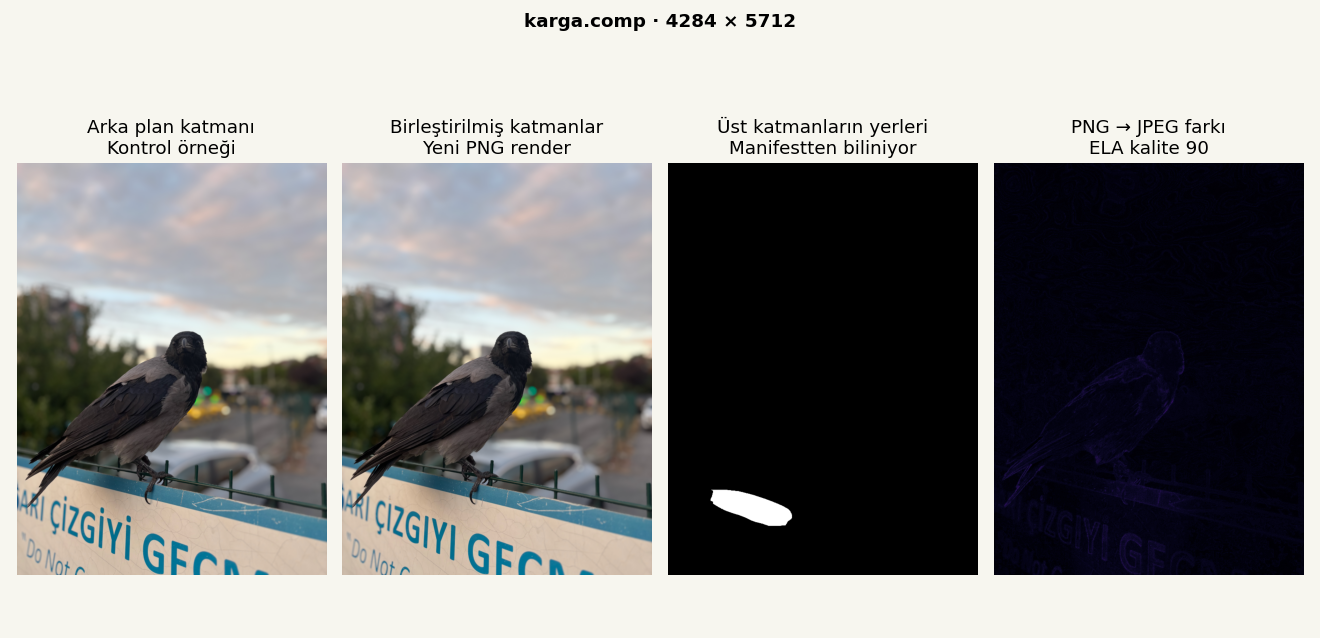


### Aynı alanı sayıyla karşılaştıralım

Bu sayılar üst katmanların kapladığı piksellerdeki ortalama ELA farkıdır. Büyük sayı daha çok yeniden sıkıştırma farkı demek; sahte olma yüzdesi değildir. Bazı ayarlarda kontrol ve render birbirine yakın çıkabilir.

| JPEG kalitesi | Katman alanında kontrol farkı | Katman alanında render farkı |
|---|---:|---:|
| 5 | 9.038 | 8.750 |
| 10 | 5.239 | 5.104 |
| 20 | 2.674 | 2.571 |
| 40 | 1.608 | 1.525 |
| 60 | 1.388 | 1.342 |
| 80 | 0.928 | 0.897 |
| 90 | 0.661 | 0.640 |
| 95 | 0.531 | 0.518 |

**Bu örnekte Q90:** katman alanının ortalama farkı kontrolde **0.661**, render'da **0.640**. Bu ölçüm artmadı; biraz daha düşük çıktı. Bu bir tespit doğruluğu ölçümü değil.


### Bütün kalite ayarları

Üst iki sıra kontrolün, alt iki sıra yeni render'ın haritaları. Hepsinde renk ölçeği **0–20**; üstündeki değerler aynı en parlak renkte görünür. Tablodaki ölçümler kırpılmamış değerlerden gelir.

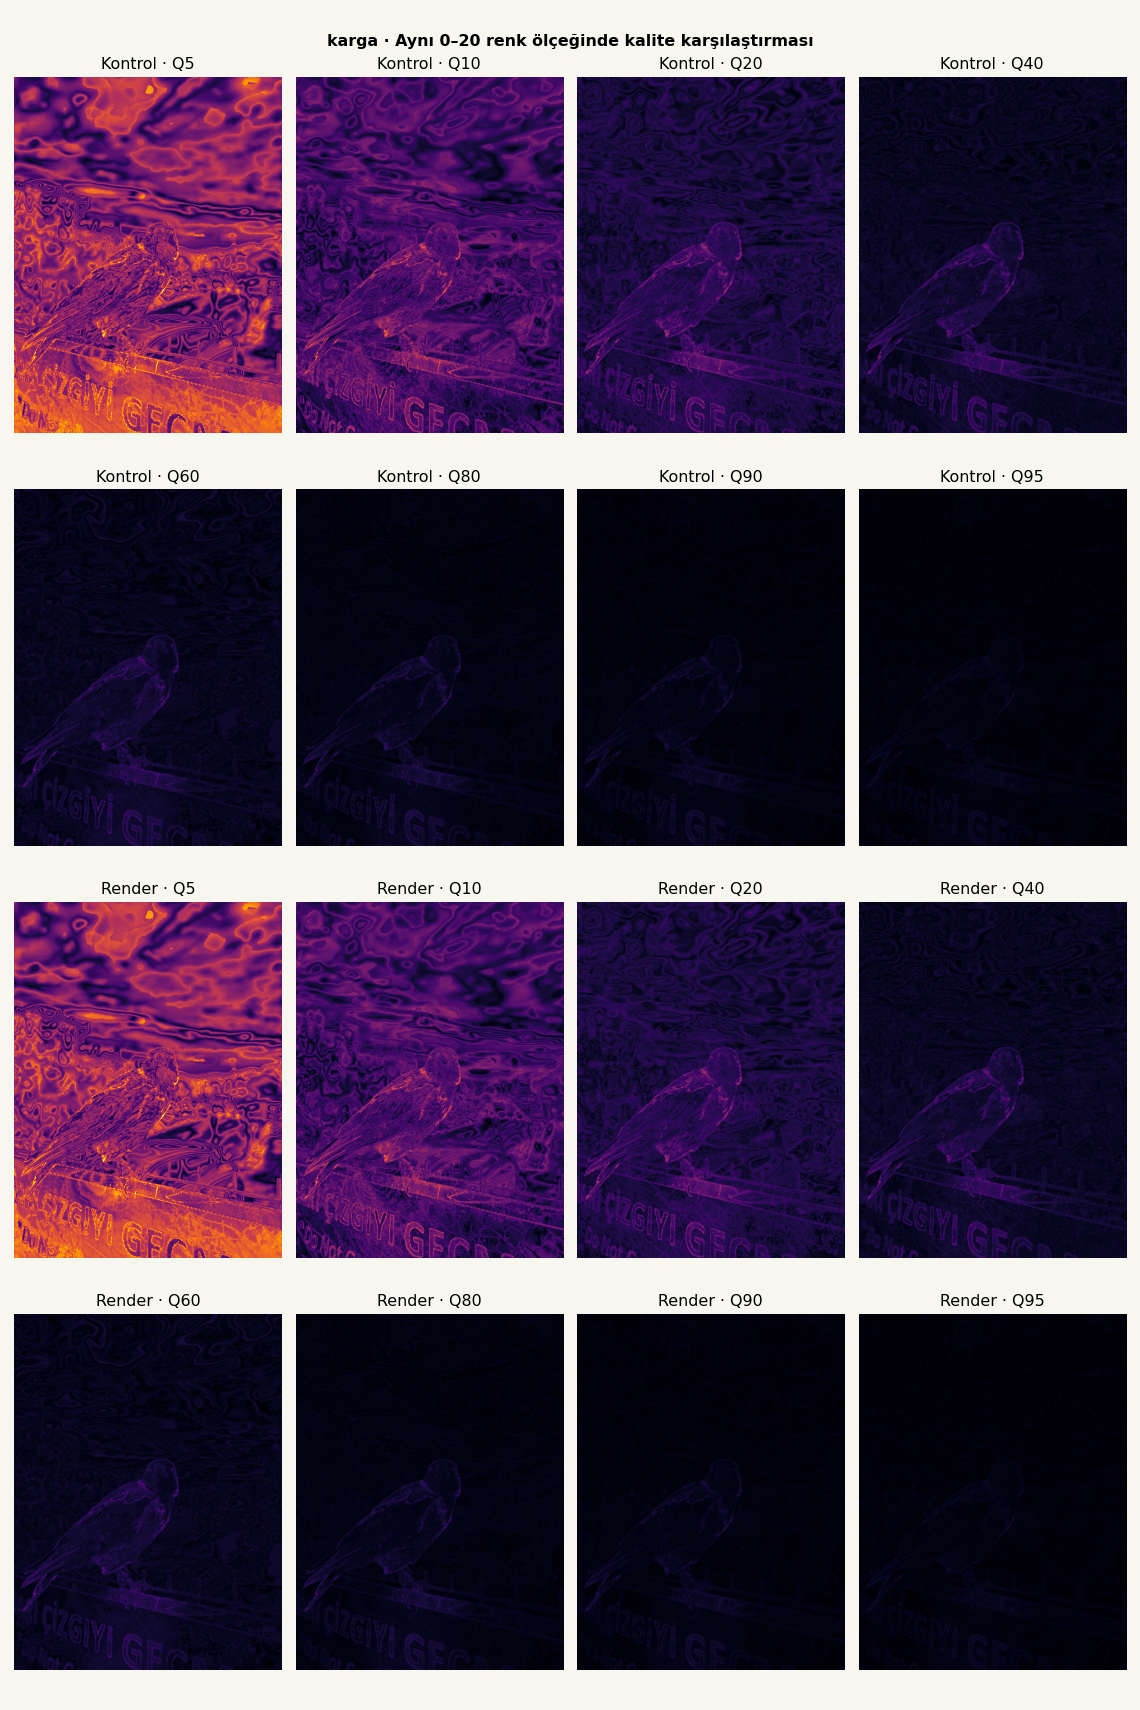


## Bu denemeden ne çıkarabiliriz?

Bu iki `.comp` paketini katmanlarından tam boyutlu PNG'ye çevirebildik. Sonra aynı kontrollü ELA hesaplarını bu görüntülere uyguladık.

Katman yerlerini bildiğimiz için aynı bölgelerin ölçümlerini karşılaştırabiliyoruz. Bu, ELA'nın o bölgeleri kendi başına tespit ettiği anlamına gelmiyor. Düşük JPEG kalitesi fotoğrafın normal bölgelerinde de büyük fark oluşturabiliyor. Katman alanındaki farkın kontrolden yüksek veya düşük olması, tek başına düzenleme kararı vermemizi sağlamaz.

[Bütün ölçümler — CSV](outputs/compositor_tests/ela_measurements.csv) · [İşlem ve render ayrıntıları — JSON](outputs/compositor_tests/report.json)
